<a href="https://colab.research.google.com/github/lin21022/Yuhsin-Lin/blob/main/try_starter_signs_v2_student.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
# Note: After you run this cell, the training and test data will be available in
# the file browser. (Click the folder icon on the left to view it)
#
# If you don't see the data after the cell completes, click the refresh button
# in the file browser (folder icon with circular arrow)

# First, let's download and unzip the data
!echo "Downloading files..."
!wget -q https://github.com/byui-cse/cse450-course/raw/master/data/roadsigns/training1.zip
!wget -q https://github.com/byui-cse/cse450-course/raw/master/data/roadsigns/training2.zip
!wget -q https://github.com/byui-cse/cse450-course/raw/master/data/roadsigns/holdout.zip
!wget -q https://github.com/byui-cse/cse450-course/raw/master/data/roadsigns/mini_holdout.zip
!wget -q https://github.com/byui-cse/cse450-course/raw/master/data/roadsigns/mini_holdout_answers.csv

!echo "Unzipping files..."
!unzip -q /content/training1.zip
!unzip -q /content/training2.zip
!unzip -q /content/holdout.zip
!unzip -q /content/mini_holdout.zip

# Combine the two traning directories
!echo "Merging training data..."
!mkdir /content/training
!mv /content/training1/* /content/training
!mv /content/training2/* /content/training

# Cleanup
!echo "Cleaning up..."
!rmdir /content/training1
!rmdir /content/training2
!rm training1.zip
!rm training2.zip
!rm holdout.zip
!rm mini_holdout.zip

!echo "Data ready."

Unzipping files...
Merging training data...
Cleaning up...
Data ready.


In [2]:
# Import libraries
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import matplotlib.pyplot as plt
import numpy as np

!pip install -q lets-plot
from lets_plot import *

LetsPlot.setup_html()


In [6]:
# We're using keras' ImageDataGenerator class to load our image data.
# See (https://keras.io/api/preprocessing/image/#imagedatagenerator-class) for details
#
# A couple of things to note:
# 1. We're specifying a number for the seed, so we'll always get the same shuffle and split of our images.
# 2. Class names are inferred automatically from the image subdirectory names.
# 3. We're splitting the training data into 80% training, 20% validation.


training_dir = '/content/training/'
image_size = (100, 100)

# Split up the training data images into training and validations sets
# We'll use and ImageDataGenerator to do the splits
# ImageDataGenerator can also be used to do preprocessing and agumentation on the files as can be seen with rescale

train_datagen = ImageDataGenerator(
        rescale=1./255,
        validation_split=.2,
        # Geometric augmentation
        rotation_range=10,
        width_shift_range=0.08,
        height_shift_range=0.08,
        zoom_range=0.10,
        shear_range=0.05,

        # Lighting and color augmentation
        brightness_range=(0.7, 1.3),
        channel_shift_range=10,

        fill_mode="nearest"
        )
validation_datagen = ImageDataGenerator(
        rescale=1./255,
        validation_split=.2
        )

train_generator = train_datagen.flow_from_directory(
        training_dir,
        target_size = image_size,
        subset="training",
        batch_size=32,
        class_mode='sparse',
        seed=42,shuffle=True)
validation_generator = validation_datagen.flow_from_directory(
        training_dir,
        target_size=image_size,
        batch_size=32,
        class_mode='sparse',
        subset="validation",
        seed=42)



Found 31368 images belonging to 43 classes.
Found 7841 images belonging to 43 classes.


In [7]:
import numpy as np

print("Number of classes:", train_generator.num_classes)
print("Class mapping:", train_generator.class_indices)

train_counts = np.bincount(train_generator.classes)
val_counts = np.bincount(validation_generator.classes)

print("Training samples:", train_generator.samples)
print("Validation samples:", validation_generator.samples)
print("Training class counts:", train_counts)
print("Validation class counts:", val_counts)

Number of classes: 43
Class mapping: {'00000': 0, '00001': 1, '00002': 2, '00003': 3, '00004': 4, '00005': 5, '00006': 6, '00007': 7, '00008': 8, '00009': 9, '00010': 10, '00011': 11, '00012': 12, '00013': 13, '00014': 14, '00015': 15, '00016': 16, '00017': 17, '00018': 18, '00019': 19, '00020': 20, '00021': 21, '00022': 22, '00023': 23, '00024': 24, '00025': 25, '00026': 26, '00027': 27, '00028': 28, '00029': 29, '00030': 30, '00031': 31, '00032': 32, '00033': 33, '00034': 34, '00035': 35, '00036': 36, '00037': 37, '00038': 38, '00039': 39, '00040': 40, '00041': 41, '00042': 42}
Training samples: 31368
Validation samples: 7841
Training class counts: [ 168 1776 1800 1128 1584 1488  336 1152 1128 1176 1608 1056 1680 1728
  624  504  336  888  960  168  288  264  312  408  216 1200  480  192
  432  216  360  624  192  552  336  960  312  168 1656  240  288  192
  192]
Validation class counts: [ 42 444 450 282 396 372  84 288 282 294 402 264 420 432 156 126  84 222
 240  42  72  66  78 10

In [5]:
#these might come in handy
target_names = ['Speed_20', 'Speed_30', 'Speed_50', 'Speed_60', 'Speed_70',
               'Speed_80','Speed_Limit_Ends', 'Speed_100', 'Speed_120', 'Overtaking_Prohibited',
               'Overtakeing_Prohibited_Trucks', 'Priority', 'Priority_Road_Ahead', 'Yield', 'STOP',
               'Entry_Forbidden', 'Trucks_Forbidden', 'No_Entry(one-way traffic)', 'General Danger(!)', 'Left_Curve_Ahead',
               'Right_Curve_Ahead', 'Double_Curve', 'Poor_Surface_Ahead', 'Slippery_Surface_Ahead', 'Road_Narrows_On_Right',
               'Roadwork_Ahead', 'Traffic_Light_Ahead', 'Warning_Pedestrians', 'Warning_Children', 'Warning_Bikes',
               'Ice_Snow', 'Deer_Crossing', 'End_Previous_Limitation', 'Turning_Right_Compulsory', 'Turning_Left_Compulsory',
               'Ahead_Only', 'Straight_Or_Right_Mandatory', 'Straight_Or_Left_Mandatory', 'Passing_Right_Compulsory', 'Passing_Left_Compulsory',
               'Roundabout', 'End_Overtaking_Prohibition', 'End_Overtaking_Prohibition_Trucks']

In [ ]:
# View 9 images and their class labels
plt.figure(figsize=(10, 10))
images, labels = next(train_generator)  # Assuming train_generator is a generator
batch_size = images.shape[0]

for i in range(min(9, batch_size)):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow((images[i] * 255).astype("uint8"))
    plt.title(int(labels[i]))
    plt.axis("off")

plt.show()

In [8]:
# Build a model...
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Conv2D, MaxPooling2D, BatchNormalization,
    GlobalAveragePooling2D, Dense, Dropout
)
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.callbacks import ModelCheckpoint
from tensorflow.keras.models import load_model
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

model = Sequential([
    Conv2D(32, 3, padding="same", activation="relu",
           input_shape=(100, 100, 3)),
    BatchNormalization(),
    MaxPooling2D(),

    Conv2D(64, 3, padding="same", activation="relu"),
    BatchNormalization(),
    MaxPooling2D(),

    Conv2D(128, 3, padding="same", activation="relu"),
    BatchNormalization(),
    MaxPooling2D(),

    Conv2D(256, 3, padding="same", activation="relu"),
    BatchNormalization(),
    MaxPooling2D(),

    GlobalAveragePooling2D(),
    Dense(256, activation="relu"),
    Dropout(0.4),
    Dense(43, activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=3e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)




/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [9]:
checkpoint_path = "/content/traffic_sign_model_checkpoint.keras"

checkpoint_callback = ModelCheckpoint(
    filepath=checkpoint_path,
    monitor='val_accuracy',
    save_best_only=True,
    mode='max',
    verbose=1
)

early_stopping = EarlyStopping(
    monitor='val_accuracy',
    patience=4,          # Stop if no improvement for 4 epochs
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,          # Multiply learning rate by 0.2
    patience=2,          # Wait 2 epochs before reducing
    min_lr=1e-6
)

callbacks_list = [checkpoint_callback, early_stopping, reduce_lr]


history = model.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=30,
    callbacks=callbacks_list
)

Epoch 1/30
981/981 ━━━━━━━━━━━━━━━━━━━━ 0s 147ms/step - accuracy: 0.2602 - loss: 2.7589
Epoch 1: val_accuracy improved from None to 0.62428, saving model to /content/traffic_sign_model_checkpoint.keras

Epoch 1: finished saving model to /content/traffic_sign_model_checkpoint.keras
981/981 ━━━━━━━━━━━━━━━━━━━━ 172s 158ms/step - accuracy: 0.4177 - loss: 2.0801 - val_accuracy: 0.6243 - val_loss: 1.3044 - learning_rate: 3.0000e-04
Epoch 2/30
981/981 ━━━━━━━━━━━━━━━━━━━━ 0s 130ms/step - accuracy: 0.8383 - loss: 0.6116
Epoch 2: val_accuracy improved from 0.62428 to 0.90639, saving model to /content/traffic_sign_model_checkpoint.keras

Epoch 2: finished saving model to /content/traffic_sign_model_checkpoint.keras
981/981 ━━━━━━━━━━━━━━━━━━━━ 133s 136ms/step - accuracy: 0.8951 - loss: 0.4180 - val_accuracy: 0.9064 - val_loss: 0.3435 - learning_rate: 3.0000e-04
Epoch 3/30
981/981 ━━━━━━━━━━━━━━━━━━━━ 0s 131ms/step - accuracy: 0.9706 - loss: 0.1347
Epoch 3: val_accuracy improved from 0.90639 to 

In [10]:

# Convert Keras history to a DataFrame
history_df = pd.DataFrame(history.history)
history_df["epoch"] = range(1, len(history_df) + 1)

# Create a long-format DataFrame
plot_df = pd.DataFrame({
    "epoch": list(history_df["epoch"]) * 4,
    "value": (
        list(history_df["accuracy"]) +
        list(history_df["val_accuracy"]) +
        list(history_df["loss"]) +
        list(history_df["val_loss"])
    ),
    "metric": (
        ["Accuracy"] * len(history_df) +
        ["Accuracy"] * len(history_df) +
        ["Loss"] * len(history_df) +
        ["Loss"] * len(history_df)
    ),
    "dataset": (
        ["Training"] * len(history_df) +
        ["Validation"] * len(history_df) +
        ["Training"] * len(history_df) +
        ["Validation"] * len(history_df)
    )
})

# Plot using Lets-Plot
(
    ggplot(plot_df, aes(x="epoch", y="value", color="dataset"))
    + geom_line(size=1.2)
    + geom_point(size=2)
    + facet_grid(y="metric", scales="free_y")
    + labs(
        title="Training and Validation Performance",
        x="Epoch",
        y="Value",
        color="Dataset"
    )
    + theme_minimal()
    + ggsize(900, 600)
)

In [11]:
import numpy as np
from sklearn.metrics import accuracy_score, f1_score

validation_generator.reset()

y_true = []
y_pred = []

for batch_index in range(len(validation_generator)):
    images, labels = validation_generator[batch_index]

    predictions = model.predict(images, verbose=0)
    predicted_classes = np.argmax(predictions, axis=1)

    y_true.extend(labels.astype(int))
    y_pred.extend(predicted_classes)

# Remove any extra samples
y_true = np.array(y_true[:validation_generator.samples])
y_pred = np.array(y_pred[:validation_generator.samples])

accuracy = accuracy_score(y_true, y_pred)
micro_f1 = f1_score(y_true, y_pred, average="micro")
macro_f1 = f1_score(y_true, y_pred, average="macro")

print(f"Accuracy: {accuracy:.4f}")
print(f"Micro-F1: {micro_f1:.4f}")
print(f"Macro-F1: {macro_f1:.4f}")

Accuracy: 0.9833
Micro-F1: 0.9833
Macro-F1: 0.9699


Accuracy: 0.9833
Micro-F1: 0.9833
Macro-F1: 0.9699

Incorrect predictions: 131
Total validation images: 7841


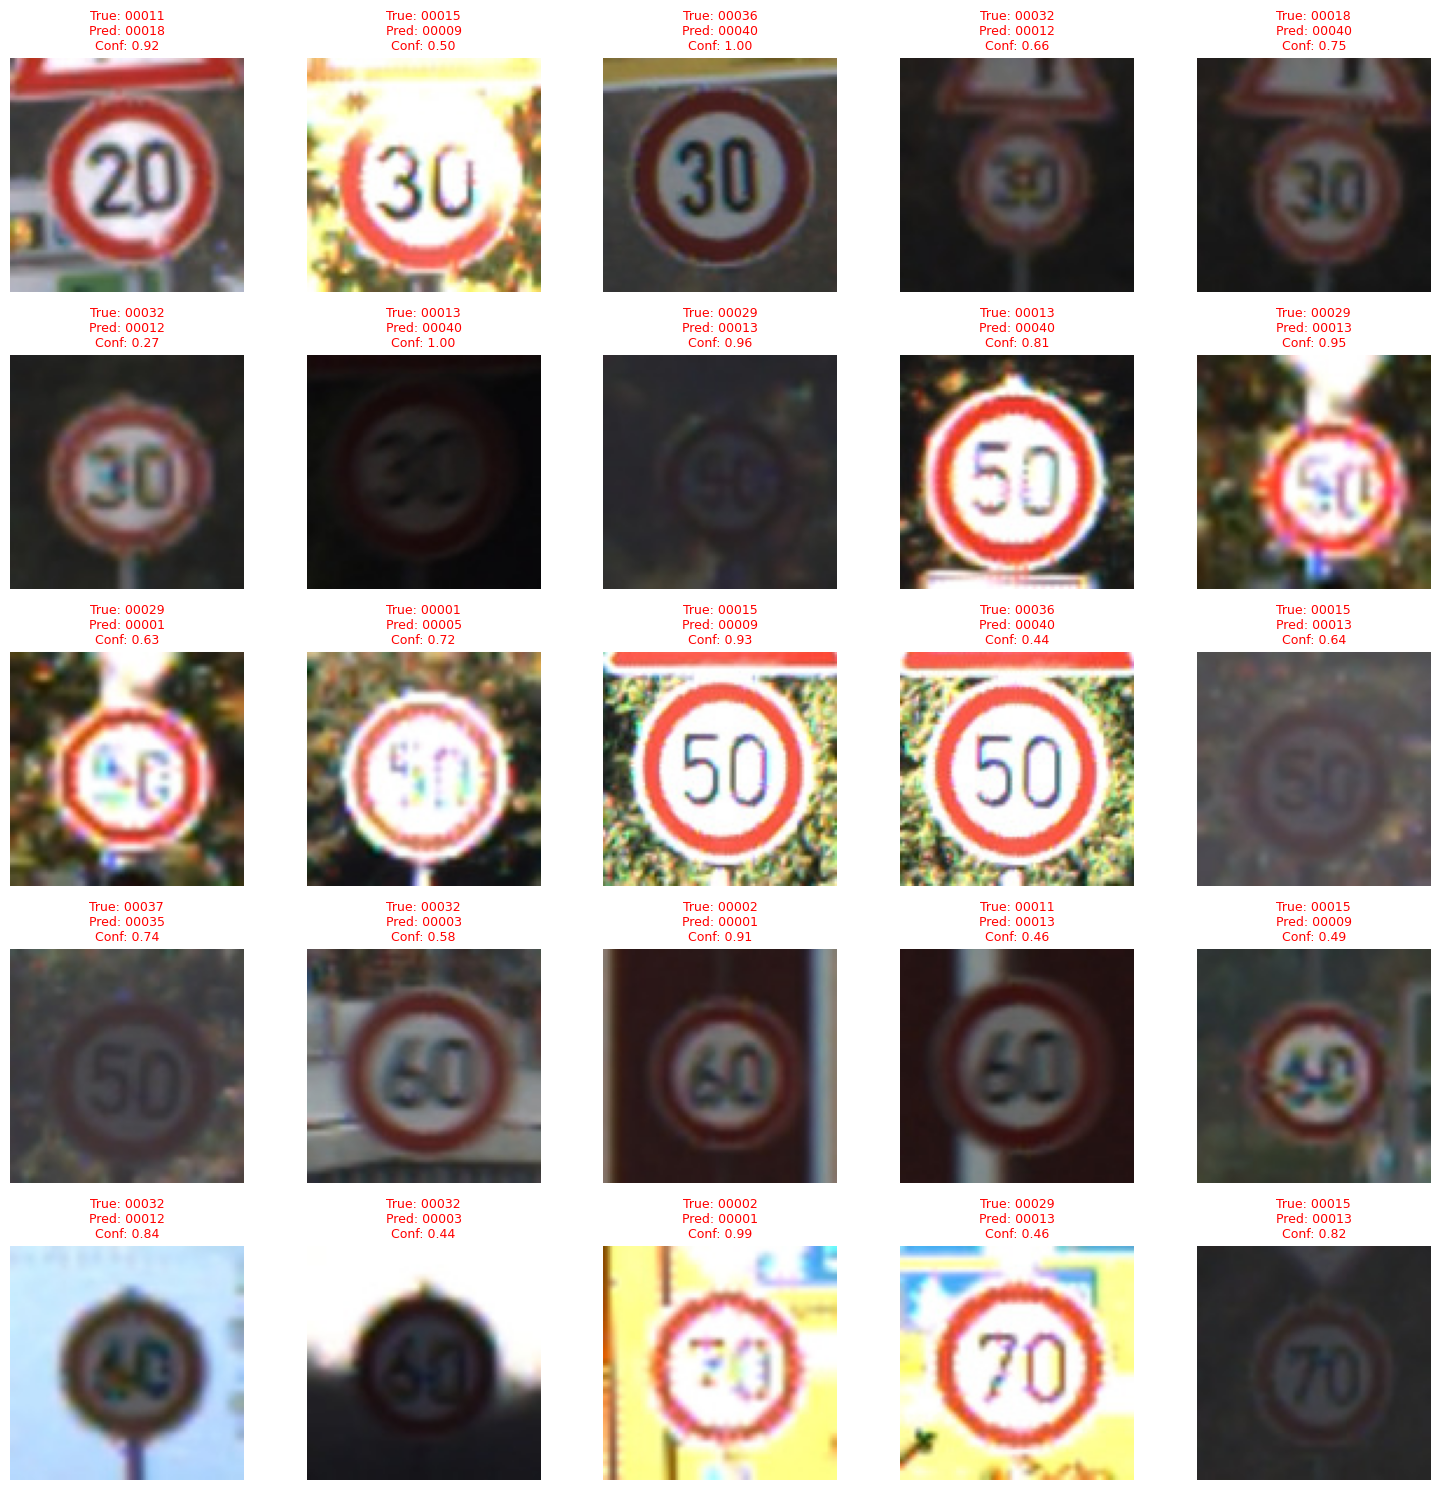

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.utils import load_img, img_to_array

# Use the best saved model
best_model = load_model("/content/traffic_sign_model_checkpoint.keras")

validation_generator.reset()

y_true = []
y_pred = []
y_confidence = []

for batch_index in range(len(validation_generator)):
    images, labels = validation_generator[batch_index]

    probabilities = best_model.predict(images, verbose=0)
    predictions = np.argmax(probabilities, axis=1)
    confidence = np.max(probabilities, axis=1)

    y_true.extend(labels.astype(int))
    y_pred.extend(predictions)
    y_confidence.extend(confidence)

y_true = np.array(y_true[:validation_generator.samples])
y_pred = np.array(y_pred[:validation_generator.samples])
y_confidence = np.array(y_confidence[:validation_generator.samples])

# Find incorrect predictions
incorrect_indices = np.where(y_true != y_pred)[0]

print("Incorrect predictions:", len(incorrect_indices))
print("Total validation images:", validation_generator.samples)

# Convert class numbers back to folder names
class_names = {
    value: key for key, value in validation_generator.class_indices.items()
}

# Display up to 25 incorrect images
number_to_display = min(25, len(incorrect_indices))

plt.figure(figsize=(15, 15))

for plot_index, image_index in enumerate(
    incorrect_indices[:number_to_display]
):
    image_path = validation_generator.filepaths[image_index]
    image = load_img(image_path, target_size=(100, 100))

    true_label = class_names[y_true[image_index]]
    predicted_label = class_names[y_pred[image_index]]
    confidence = y_confidence[image_index]

    plt.subplot(5, 5, plot_index + 1)
    plt.imshow(image)
    plt.axis("off")
    plt.title(
        f"True: {true_label}\n"
        f"Pred: {predicted_label}\n"
        f"Conf: {confidence:.2f}",
        fontsize=9,
        color="red"
    )

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import load_model
from tensorflow.keras.utils import load_img

# Use the best saved model
best_model = load_model("/content/traffic_sign_model_checkpoint.keras")

validation_generator.reset()

y_true = []
y_pred = []
y_confidence = []

for batch_index in range(len(validation_generator)):
    images, labels = validation_generator[batch_index]

    probabilities = best_model.predict(images, verbose=0)
    predictions = np.argmax(probabilities, axis=1)
    confidence = np.max(probabilities, axis=1)

    y_true.extend(labels.astype(int))
    y_pred.extend(predictions)
    y_confidence.extend(confidence)

y_true = np.array(y_true[:validation_generator.samples])
y_pred = np.array(y_pred[:validation_generator.samples])
y_confidence = np.array(y_confidence[:validation_generator.samples])

# Find incorrect predictions
incorrect_indices = np.where(y_true != y_pred)[0]

print("Incorrect predictions:", len(incorrect_indices))
print("Total validation images:", validation_generator.samples)

# Map generator index -> folder name -> human-readable sign name
class_names = {
    value: target_names[int(key)]
    for key, value in validation_generator.class_indices.items()
}

# Display up to 25 incorrect images
number_to_display = min(25, len(incorrect_indices))

plt.figure(figsize=(15, 15))

for plot_index, image_index in enumerate(incorrect_indices[:number_to_display]):
    image_path = validation_generator.filepaths[image_index]
    image = load_img(image_path, target_size=(100, 100))

    true_label = class_names[y_true[image_index]]
    predicted_label = class_names[y_pred[image_index]]
    confidence = y_confidence[image_index]

    plt.subplot(5, 5, plot_index + 1)
    plt.imshow(image)
    plt.axis("off")
    plt.title(
        f"True: {true_label}\n"
        f"Pred: {predicted_label}\n"
        f"Conf: {confidence:.2f}",
        fontsize=8,
        color="red"
    )

plt.tight_layout()
plt.show()

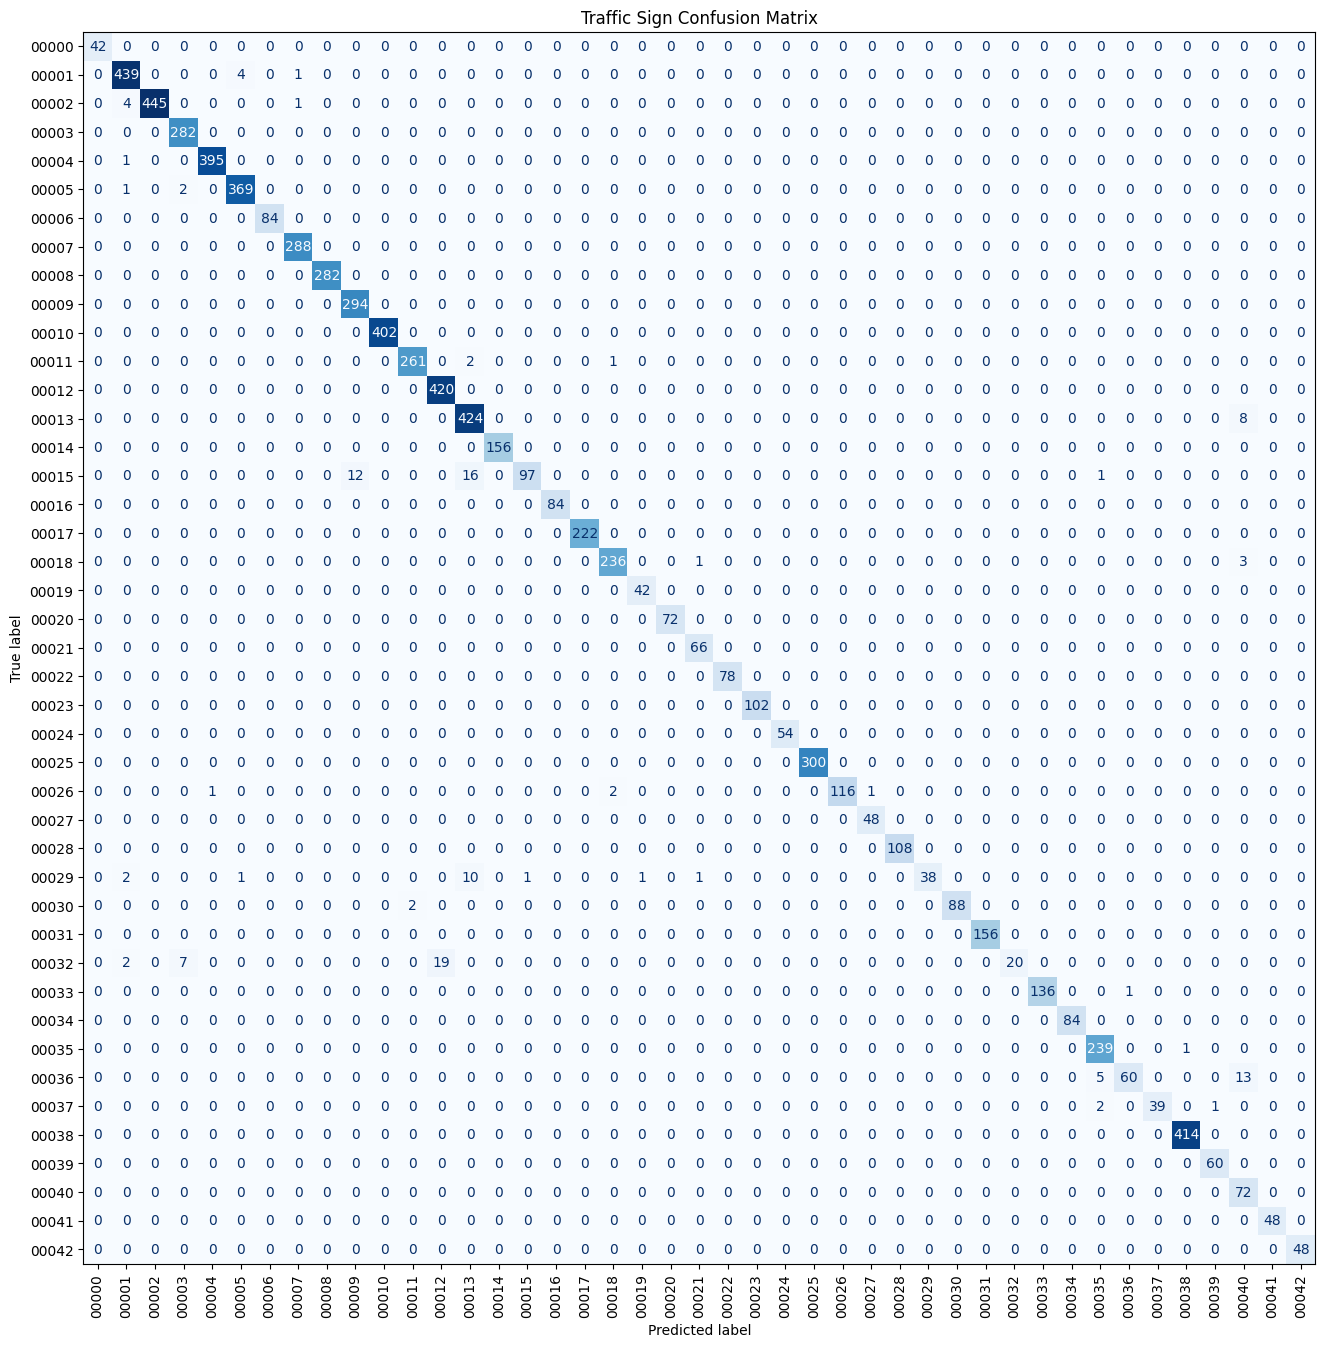

In [13]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=list(validation_generator.class_indices.keys())
)

fig, ax = plt.subplots(figsize=(16, 16))
disp.plot(ax=ax, xticks_rotation="vertical", cmap="Blues", colorbar=False)
plt.title("Traffic Sign Confusion Matrix")
plt.show()

## Testing the model
Once you have built and trained your model, the next step is to run the mini holdout images through it and see how well your model does at making predictions for images it has never seen before.

Since loading these images and formatting them for the model can be tricky, you may find the following code useful. This code only uses your model to predict the class label for a given image. You'll still need to compare those predictions to the "ground truth" class labels in `mini_holdout_answers.csv` to evaluate how well the model does.

Previously, you were given a file that would check your results. This time you're given the answers to the first mini holdout dataset. You'll need to compare those predictions against the "ground truth" class labels in `mini_holdout_answers.csv` to evaluate how well the model does.

Make sure to use the insights gained from the mini hold out dataset in your executive summary.


```
from tensorflow.keras.preprocessing import image_dataset_from_directory
test_dir = '/content/'

test_datagen = ImageDataGenerator(rescale=1./255)
test_generator = test_datagen.flow_from_directory(
        test_dir,
        classes=['mini_holdout'],
        target_size=image_size,
        class_mode='sparse',
        shuffle=False)
probabilities = model.predict(test_generator)
predictions = [np.argmax(probas) for probas in probabilities]
```



##Mini Hold out Dataset


Once you feel confident, you will need to predict for the full holdout dataset using the following code, and submit your csv file:

```
from tensorflow.keras.preprocessing import image_dataset_from_directory
test_dir = '/content/'

test_datagen = ImageDataGenerator(rescale=1./255)
test_generator = test_datagen.flow_from_directory(
        test_dir,
        classes=['holdout'],
        target_size=image_size,
        class_mode='sparse',
        shuffle=False)
probabilities = model.predict(test_generator)
predictions = [np.argmax(probas) for probas in probabilities]
```